Link a Google Colab: https://colab.research.google.com/drive/1B0sVXiSdokVaQAgPQCRJH95zwomsz84i?usp=sharing#scrollTo=QjoF8jwLMrEW

**Análisis Exploratorio y Preprocesamiento de Datos (EDA)**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/stroke-prediction-dataset


Carga e inspeccion inicial

In [ ]:
import pandas as pd
import os

# Find the CSV file inside the downloaded directory
files = os.listdir(path)
csv_files = [f for f in files if f.endswith('.csv')]

if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(df.head(5))
    print(df.tail(5))
    print(df.info())
    print(df.describe())
    print(df.isnull().sum())
else:
    print(f"No CSV files found in {path}. Available files: {files}")

      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  
         id  gender   age  hypertension  heart_disease e

 Limpieza, Transformación y Tratamiento

In [ ]:
import numpy as np

bmi_mean = df['bmi'].mean()
print(f"Mean BMI (excluding nulls): {bmi_mean:.2f}")

df['bmi'] = df['bmi'].fillna(bmi_mean)


print("\nMissing values after imputation:")
print(df.isnull().sum())

variables_continuas = df.select_dtypes(include=['float64']).columns
for col in variables_continuas:
 q1 = np.percentile(df[col], 25)
 q3 = np.percentile(df[col], 75)
 iqr = q3 - q1

# Calcular los límites inferior y superior
limite_inferior = q1 - (1.5 * iqr)
limite_superior = q3 + (1.5 * iqr)

print(f"--- Variable: {col} ---")
print(f"Q1: {q1} | Q3: {q3} | IQR: {iqr}")
print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}\n")

df=pd.get_dummies(df)
df.drop(columns='id', inplace=True)

Mean BMI (excluding nulls): 28.89

Missing values after imputation:
id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64
--- Variable: bmi ---
Q1: 23.8 | Q3: 32.8 | IQR: 8.999999999999996
Límite inferior: 10.300000000000006
Límite superior: 46.29999999999999



Análisis Visual y Exploratorio

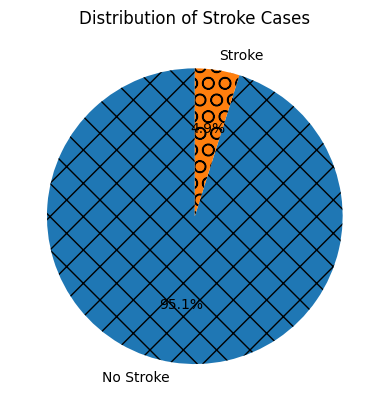

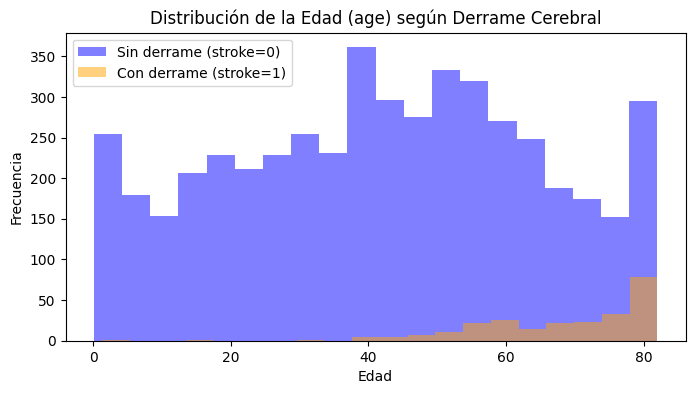

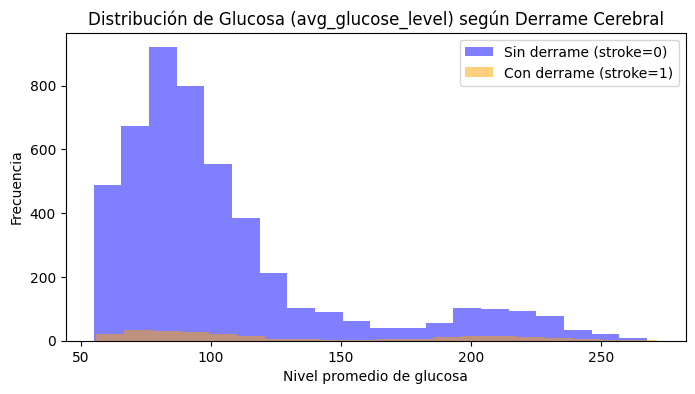

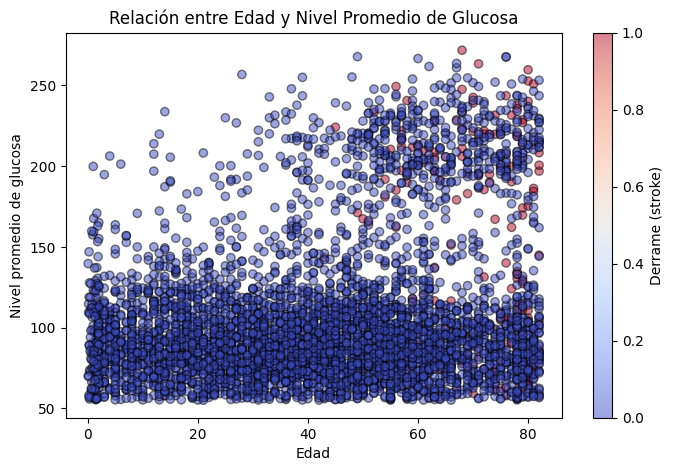

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

counts = df['stroke'].value_counts()
valores = [counts[0], counts[1]]

etiquetas = ['No Stroke', 'Stroke']
patrones = ["X", "O"]

fig, ax = plt.subplots()
ax.pie(valores, labels=etiquetas, hatch=patrones, autopct='%1.1f%%', startangle=90)
ax.set_title("Distribution of Stroke Cases")
plt.show()

# 1. Histograma para la variable 'age' dividido por 'stroke'
plt.figure(figsize=(8, 4))
plt.hist(df[df['stroke'] == 0]['age'], bins=20, alpha=0.5, label='Sin derrame (stroke=0)', color='blue')
plt.hist(df[df['stroke'] == 1]['age'], bins=20, alpha=0.5, label='Con derrame (stroke=1)', color='orange')
plt.title('Distribución de la Edad (age) según Derrame Cerebral')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

# 2. Histograma para la variable 'avg_glucose_level' dividido por 'stroke'
plt.figure(figsize=(8, 4))
plt.hist(df[df['stroke'] == 0]['avg_glucose_level'], bins=20, alpha=0.5, label='Sin derrame (stroke=0)', color='blue')
plt.hist(df[df['stroke'] == 1]['avg_glucose_level'], bins=20, alpha=0.5, label='Con derrame (stroke=1)', color='orange')
plt.title('Distribución de Glucosa (avg_glucose_level) según Derrame Cerebral')
plt.xlabel('Nivel promedio de glucosa')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

# 3. Gráfico de dispersión (Scatter Plot) de Edad vs Nivel promedio de glucosa
x = np.array(df['age'])
y = np.array(df['avg_glucose_level'])
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.5, c=df['stroke'], cmap='coolwarm', edgecolors='k')
plt.title('Relación entre Edad y Nivel Promedio de Glucosa')
plt.xlabel('Edad')
plt.ylabel('Nivel promedio de glucosa')
cbar = plt.colorbar()
cbar.set_label('Derrame (stroke)')
plt.show()